## Abruf der Teilprogramme und Ergebnis Darstellung

In [2]:
#IMPORTS allgemein
import os
import pandas as pd
import matplotlib.pyplot as plt

#HILFSFUNKTIONEN
from merge_teilprojekte_test.functions.hilfsfunktionen import *

#PV IMPORTS
from merge_teilprojekte_test.functions.functions_weather_data import DWDWeatherConfig, DWDWeatherFetcher
from merge_teilprojekte_test.functions.pv_baukasten import PV_System, PV_TYPEN

#INDUSTRIE IMPORT
from merge_teilprojekte_test.functions.Industriegebiet import IndustryLoadAggregator

#ENERGIELANDSCHAFT IMPORT
from merge_teilprojekte_test.functions.Energielandschaft import main

In [3]:
# ------------------------------------------------------------
# 1) Wetterdaten laden (CSV ODER DWD)
# ------------------------------------------------------------
#WETTERDATEN CSV
USE_EXISTING_WEATHER = True
weather_csv = "./functions/inputs/wetter_daten_15min.csv"

print("→ Verwende vorhandene Wetterdaten-CSV")
weather_df = pd.read_csv(weather_csv, index_col=0, parse_dates=True)
print(weather_df)
weather_df.index = pd.to_datetime(weather_df.index, utc=True).tz_convert(None)

'''
else:
	print("→ Hole Wetterdaten neu vom DWD")
	cfg = DWDWeatherConfig(
		coords=(51.08579, 6.47554),
		start="2022-01-01",
		end="2022-12-31",
		station_id=None,
		auto_select=False,
		min_quality=0.95,
		save_path=weather_csv,
	)
	weather_df = DWDWeatherFetcher(cfg).run()
'''

→ Verwende vorhandene Wetterdaten-CSV
                           rel_hum  pressure_pa  ghi  dhi  temp_air  \
date                                                                  
2022-01-01 00:00:00+01:00    84.05     101880.0  0.0  0.0  13.10000   
2022-01-01 00:15:00+01:00    84.08     101890.0  0.0  0.0  13.10030   
2022-01-01 00:30:00+01:00    84.12     101840.0  0.0  0.0  13.20002   
2022-01-01 00:45:00+01:00    84.07     101820.0  0.0  0.0  13.29000   
2022-01-01 01:00:00+01:00    84.00     101870.0  0.0  0.0  13.30000   
...                            ...          ...  ...  ...       ...   
2022-12-31 22:45:00+01:00    89.20      99985.0  0.0  0.0  13.20000   
2022-12-31 23:00:00+01:00    91.10     100000.0  0.0  0.0  13.00000   
2022-12-31 23:15:00+01:00    90.60     100015.0  0.0  0.0  13.25000   
2022-12-31 23:30:00+01:00    90.10     100030.0  0.0  0.0  13.50000   
2022-12-31 23:45:00+01:00    90.10     100030.0  0.0  0.0  13.50000   

                            temp_dew  

'\nelse:\n\tprint("→ Hole Wetterdaten neu vom DWD")\n\tcfg = DWDWeatherConfig(\n\t\tcoords=(51.08579, 6.47554),\n\t\tstart="2022-01-01",\n\t\tend="2022-12-31",\n\t\tstation_id=None,\n\t\tauto_select=False,\n\t\tmin_quality=0.95,\n\t\tsave_path=weather_csv,\n\t)\n\tweather_df = DWDWeatherFetcher(cfg).run()\n'

In [4]:
print(weather_df)
print(weather_df.duplicated())

                     rel_hum  pressure_pa  ghi  dhi  temp_air   temp_dew  \
date                                                                       
2021-12-31 23:00:00    84.05     101880.0  0.0  0.0  13.10000  10.691200   
2021-12-31 23:15:00    84.08     101890.0  0.0  0.0  13.10030  10.692370   
2021-12-31 23:30:00    84.12     101840.0  0.0  0.0  13.20002  10.696800   
2021-12-31 23:45:00    84.07     101820.0  0.0  0.0  13.29000  10.699949   
2022-01-01 00:00:00    84.00     101870.0  0.0  0.0  13.30000  10.700000   
...                      ...          ...  ...  ...       ...        ...   
2022-12-31 21:45:00    89.20      99985.0  0.0  0.0  13.20000  11.450000   
2022-12-31 22:00:00    91.10     100000.0  0.0  0.0  13.00000  11.600000   
2022-12-31 22:15:00    90.60     100015.0  0.0  0.0  13.25000  11.750000   
2022-12-31 22:30:00    90.10     100030.0  0.0  0.0  13.50000  11.900000   
2022-12-31 22:45:00    90.10     100030.0  0.0  0.0  13.50000  11.900000   

           

In [5]:
# --------------------------------------------------
# Data Frame für Ergebnisse
# --------------------------------------------------
res_df = pd.DataFrame()

In [6]:
# --------------------------------------------------
# Directories
# --------------------------------------------------
base_input = "./functions/inputs"
output_dir = os.path.join(base_input, "punkte")
os.makedirs(output_dir, exist_ok=True)


In [7]:
# ------------------------------------------------------------
# 2) SOLARAUTOBAHN
# ------------------------------------------------------------
#INPUT für PV SOLARAUTOBAHN
geojson_file_1 = "a44_beide.geojson"
geojson_path_1 = os.path.join(base_input, "geometrien", geojson_file_1)
step_size_default = 2000

#step_size = hf.get_float_input(f'Schrittweite für PV Berechnung [default: {step_size_default}m]: ', step_size_default)
#100, [PV_TYPEN[1]]
print('\n \nPV abfrage zu folgender Geometrie:\n', geojson_file_1)
step_size_1, pv_auswahl_1 = get_pv_configuration(step_size_default, PV_TYPEN)

# hier kannst du auch mehrere Typen übergeben, z.B. [PV_TYPEN[0], PV_TYPEN[3], ...]
# 0 = Windschutzwand, 1 = Schallschutzwand, 2 = Schallschutzwand_Dach, 3 = Böschung
pv_system = PV_System(
	geojson_path=geojson_path_1,
	pvtypes=pv_auswahl_1, #[PV_TYPEN[0],PV_TYPEN[3]],
	step_size=step_size_1,             # Punktabstand in m
	weather_df=weather_df,
	base_output_dir=output_dir,
)

# ------------------------------------------------------------
# 3) Punkte + Azimut für alle gewählten PV-Typen generieren
# ------------------------------------------------------------
pv_points_return_1 = pv_system.generate_pv_points()

print("Berechnete PV-Typen:")
for pv_type in pv_system.pvtypes:
	print(" -", pv_type)

# ------------------------------------------------------------
# 4) Jahresenergie je PV-Typ simulieren + Zeitreihe plotten
# ------------------------------------------------------------
print("\nJahresenergie je PV-Typ:")
for pv_type in pv_system.pvtypes:
	# CSV-Name so, wie ihn generate_pv_points gespeicher hat
	csv_name = f"punkte_{pv_type.id}_{pv_type.name}.csv".replace(" ", "_")
	csv_path = os.path.join(output_dir, csv_name)

	energy_kwh_1, total_ac_1 = pv_system.simulate_pv_type_energy(pv_type, csv_path)
	total_ac_1 = total_ac_1.clip(lower=0)
	print(f"  {pv_type.name}: {energy_kwh_1:.1f} kWh")
	res_df[pv_type.name] = total_ac_1.values


 
PV abfrage zu folgender Geometrie:
 a44_beide.geojson

PV-SYSTEM KONFIGURATION

📋 Verfügbare PV-Typen:
   [1] Windschutzwand
   [2] Schallschutzwand
   [3] Schallschutzwand_Dach
   [4] Böschung
   [5] Freifläche_bzw_Agri_geneigt
   [6] Agri_vertikal
   [7] Haus_Dach
Berechnete PV-Typen:
 - [1] Windschutzwand

Jahresenergie je PV-Typ:
  Windschutzwand: 729.7 kWh


In [8]:
#--------------------------------------------------------
#INDUSTRIEGEBIET
#--------------------------------------------------------
df_industrie = pd.DataFrame()
df_industrie = IndustryLoadAggregator().run_interactive() #return lastgang als df oder output path
#falls output path, dann die csv einlesen
res_df['Last_Industrie [kW]'] = df_industrie['Gesamtlast [kW]']
print(df_industrie.head())
print(df_industrie.describe())
print(res_df.head())
print(res_df.describe())

Welche Daten sollen genutzt werden?
1) Ohne Wärme/Kälte Stromverbrauch (Nutzung fossiler Energiequellen für Wärme, keine Kälte)
2) Mit Wärme/Kälte Stromverbrauch (Nutzung reversibler Luftwärmepumpen und Geothermie-Sonden)
Modus: Mit Wärme/Kälte ausgewählt.

Verfügbare Unternehmen:
1. Entsorgung: 
5 1/2 Tage Woche, Kein Schichtbetrieb, Anlehnung an Schönmackers Umweltdienste

2. Stahl: 
5 Tage Woche, 3-Schicht-Betrieb, Anlehnung an TecPro

3. Logistik und Lagerung: 
5 Tage Woche, Teilweise Samstag und Sonntag Betrieb, Kein Schichtbetrieb, Anlehnung an CTJ Janssen

4. Schrott- und Metallhandel: 
5 Tage Woche, Kein Schichtbetrieb, Anlehnung an Willi Jenner

5. Lagerung: 
5 Tage Woche, Kein Schichtbetrieb, Anlehnung an Kleine Logistik

6. Büro: 
5 Tage Woche, Kein Schichtbetrieb, Anlehnung an Marvin Wickenhäuser

7. Logistik Lebensmittel: 
6 1/2 Tage Woche, Kein Schichtbetrieb, Anlehnung an CTJ Janssen

8. Stahl: 
7 Tage Woche, 2-Schicht-Betrieb, Anlehnung an TecPro

Ausgewählte Unternehme

In [9]:
#--------------------------------------------------------
#ENERGIELANDSCHAFT
#--------------------------------------------------------
#agri PV code für geojson und agri pv länge
agri_result = main(interactive=True, output_dir="./outputs")
agri_pv_laenge = agri_result.get("metadata").get('total_rows_length_m')

agri_pv_ausrichtung = agri_result.get("ausrichtung")
print('Ausrichtung: ', agri_pv_ausrichtung)

a = agri_pv_ausrichtung.lower()
print(a)

if a == "horizontal":
	pv_auswahl_2 = [PV_TYPEN[6]]
	module_pro_meter = 2
elif a == "horizontal_tracking":
	pv_auswahl_2 = [PV_TYPEN[4]]
	module_pro_meter = 2
elif a == "vertical":
	pv_auswahl_2 = [PV_TYPEN[5]]
	module_pro_meter = 1
else:
	pv_auswahl_2 = [PV_TYPEN[6]]
	module_pro_meter = 2
	print('Agri PV Typ unbestimmt, Berechnung basierend auf geneigter PV ohne Tracking')


if agri_result.get("success"):
	print("✓ Verarbeitung erfolgreich abgeschlossen!")
	print(f'Länge der PV Reihen: {agri_pv_laenge:.1f}')
else:
	print(f"✗ Verarbeitung abgebrochen: {agri_result.get('error')}")


#INPUT für PV Baukasten - ENERGIELANDSCHAFT
geojson_file_2 = "Agri_PV_Centroid.geojson"
geojson_path_2 = os.path.join(base_input, "geometrien", geojson_file_2)
step_size_default = 1000

#step_size = hf.get_float_input(f'Schrittweite für PV Berechnung [default: {step_size_default}m]: ', step_size_default)
#100, [PV_TYPEN[1]]
print('\n \nPV abfrage zu folgender Geometrie:\n', geojson_file_2)
#step_size_2, pv_auswahl_2 = get_pv_configuration(step_size_default, PV_TYPEN)

# hier kannst du auch mehrere Typen übergeben, z.B. [PV_TYPEN[0], PV_TYPEN[3], ...]
# 0 = Windschutzwand, 1 = Schallschutzwand, 2 = Schallschutzwand_Dach, 3 = Böschung
pv_system = PV_System(
	geojson_path=geojson_path_2,
	pvtypes=pv_auswahl_2, #[PV_TYPEN[0],PV_TYPEN[3]],
	step_size=step_size_default,             # Punktabstand in m
	weather_df=weather_df,
	base_output_dir=output_dir,
)

# ------------------------------------------------------------
# 3) Punkte + Azimut für alle gewählten PV-Typen generieren
# ------------------------------------------------------------
pv_points_return_2 = pv_system.generate_pv_points()

print("Berechnete PV-Typen:")
for pv_type in pv_system.pvtypes:
	print(" -", pv_type)

# ------------------------------------------------------------
# 4) Jahresenergie je PV-Typ simulieren + Zeitreihe plotten
# ------------------------------------------------------------
# CSV-Name so, wie ihn generate_pv_points gespeicher hat
csv_name = f"punkte_{pv_type.id}_{pv_type.name}.csv".replace(" ", "_")
csv_path = os.path.join(output_dir, csv_name)

print('PV Simulation:')
energy_kwh_2, total_ac_2 = pv_system.simulate_pv_type_energy(pv_type, csv_path)
total_ac_2 = total_ac_2.clip(lower=0)

print(f"  {pv_type.name}: {energy_kwh_2:.1f} kWh")

#Skalierung auf das gesamte Feld
agri_pv_energy = energy_kwh_2*agri_pv_laenge*module_pro_meter
print('Module pro Meter: ',module_pro_meter)
print('Länge der PV Reihen [m]: ',agri_pv_laenge)
print(f'Energielandschaft Gesamtproduktion: {agri_pv_energy:.2f} kWh')

agri_pv_total_ac = total_ac_2*agri_pv_laenge*module_pro_meter
res_df['Agri_PV'] = agri_pv_total_ac.values

power_15min = agri_pv_total_ac.resample("15min").interpolate("linear")
# power_15min = agri_pv_total_ac.resample('15T').mean()
print(power_15min)


PV-Flächenberechnung - Energielandschaft

[1/6] Einlesen der eingebetteten GeoJSON-Fläche...
  ✓ Polygon geladen (WGS84)
    - Fläche (WGS84): 0.00 deg²
    - Fläche (UTM): 949731.23 m²

[2/6] Abfrage der Benutzerinputs...
  ✓ PV-Ausrichtung: vertical
  ✓ Traktorparameter:
    - Breite: 12.0 m
    - Länge: 15.0 m
    - Wenderadius: 9.0 m

[3/6] Berechnung von Rand- und Fahrspurbreiten...
  ✓ Wendestreifen-Breite: 34.00 m (Formel: 2*r + l + 1)
  ✓ Fahrspur-Breite: 14.00 m (Formel: b + 2)

[4/6] Berechnung der nutzbaren Restfläche...
  ✓ Randstreifen-Marge: 34.00 m
  ✓ Nutzbare Fläche: 707329.86 m²

[5/6] Generierung der PV-Reihen (LineString-basiert)...
  ✓ Reihenparameter für 'vertical':
    - Ausrichtung: NS (Nord-Süd)
    - Reihenabstand (Zeile-zu-Zeile): 14.50 m
  ✓ Generierte PV-Reihen: 119
    - Gesamtlänge der Reihen: 48787.80 m
    - Geometrie: LineString (durchgehende Reihen)

[6/6] Export der Reihen als GeoJSON...
GeoJSON erfolgreich exportiert: ./outputs\P_02_Agri_PV_Reihen.

In [10]:
print(agri_pv_total_ac)

date
2021-12-31 23:00:00   NaN
2021-12-31 23:15:00   NaN
2021-12-31 23:30:00   NaN
2021-12-31 23:45:00   NaN
2022-01-01 00:00:00   NaN
                       ..
2022-12-31 21:45:00   NaN
2022-12-31 22:00:00   NaN
2022-12-31 22:15:00   NaN
2022-12-31 22:30:00   NaN
2022-12-31 22:45:00   NaN
Length: 35040, dtype: float64


In [11]:
print(res_df.describe())
print(res_df)

       Windschutzwand  Last_Industrie [kW]       Agri_PV
count    17779.000000         35040.000000  1.777900e+04
mean       164.346077           195.696712  1.754205e+06
std        148.450064           173.011421  2.489230e+06
min          0.000000             0.779360  0.000000e+00
25%          0.000000            63.106768  0.000000e+00
50%        145.454597           143.474146  6.979640e+05
75%        290.754737           288.195724  2.273433e+06
max        721.425410          1103.864820  1.230593e+07
       Windschutzwand  Last_Industrie [kW]  Agri_PV
0                 NaN              1.25000      NaN
1                 NaN              2.10239      NaN
2                 NaN              2.14772      NaN
3                 NaN              2.08943      NaN
4                 NaN              2.16319      NaN
...               ...                  ...      ...
35035             NaN             22.00000      NaN
35036             NaN              5.65000      NaN
35037             N

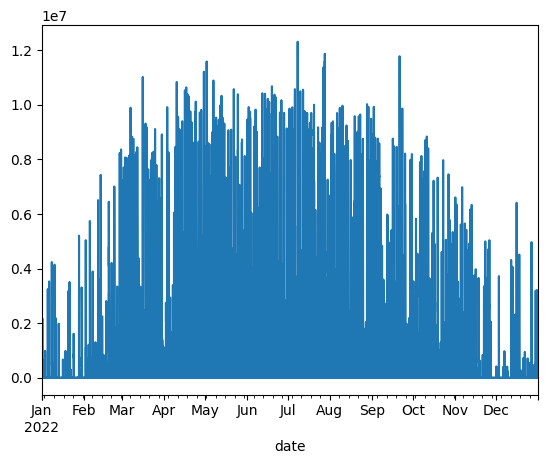

<Axes: >

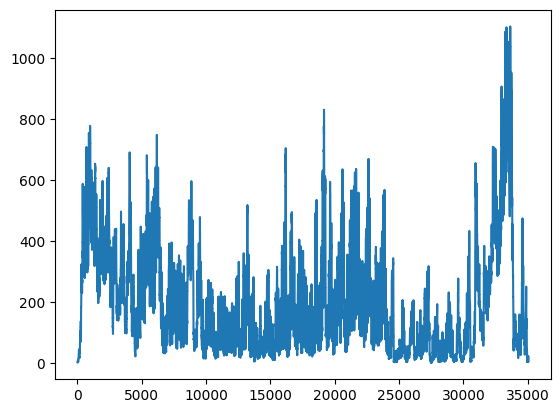

In [20]:
agri_pv_total_ac.plot()
plt.show()
res_df['Last_Industrie [kW]'].plot()

<Axes: >

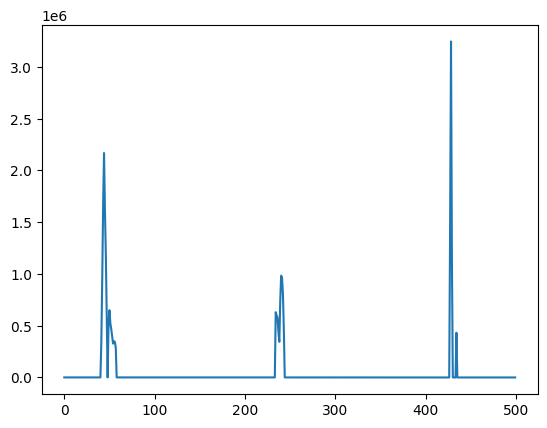

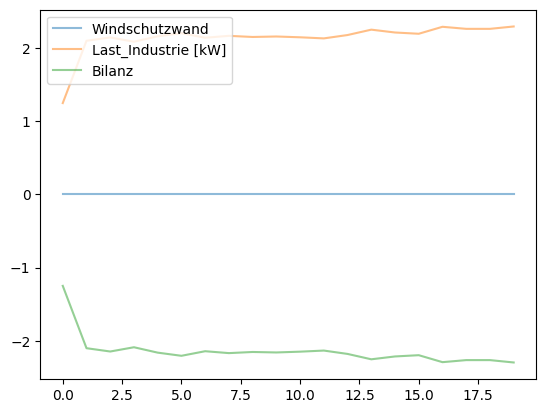

In [19]:
res_df = res_df.fillna(0)
res_df['Bilanz']= res_df['Agri_PV']+res_df['Windschutzwand']-res_df['Last_Industrie [kW]']
res_df['Bilanz'][0:500].plot()
res_df.drop(columns='Agri_PV')[0:20].plot(alpha=0.5)


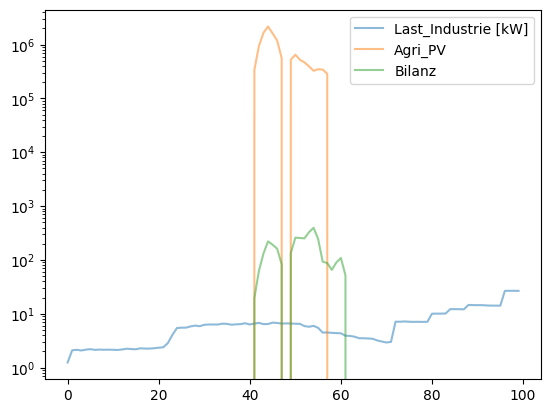

In [14]:
res_df.drop(columns='Windschutzwand')[0:100].plot(alpha=0.5)
plt.yscale("log")
plt.show()


In [15]:
print(df_industrie)

               Time stamp  \
0     2017-01-01 00:00:00   
1     2017-01-01 00:15:00   
2     2017-01-01 00:30:00   
3     2017-01-01 00:45:00   
4     2017-01-01 01:00:00   
...                   ...   
35035 2017-12-31 22:45:00   
35036 2017-12-31 23:00:00   
35037 2017-12-31 23:15:00   
35038 2017-12-31 23:30:00   
35039 2017-12-31 23:45:00   

       Lagerung: \n5 Tage Woche, Kein Schichtbetrieb, Anlehnung an Kleine Logistik\n_1  \
0                                                0.62500                                 
1                                                0.81832                                 
2                                                0.83236                                 
3                                                0.81184                                 
4                                                0.84872                                 
...                                                  ...                                 
35035                

In [16]:
print(power_15min)
df_industrie['Schallschutz_15min'] = power_15min.values

date
2021-12-31 23:00:00    NaN
2021-12-31 23:15:00    NaN
2021-12-31 23:30:00    NaN
2021-12-31 23:45:00    NaN
2022-01-01 00:00:00    NaN
                      ... 
2022-12-31 21:45:00    0.0
2022-12-31 22:00:00    0.0
2022-12-31 22:15:00    0.0
2022-12-31 22:30:00    0.0
2022-12-31 22:45:00    0.0
Freq: 15min, Length: 35040, dtype: float64


In [17]:
print(res_df)

       Windschutzwand  Last_Industrie [kW]  Agri_PV    Bilanz
0                 0.0              1.25000      0.0  -1.25000
1                 0.0              2.10239      0.0  -2.10239
2                 0.0              2.14772      0.0  -2.14772
3                 0.0              2.08943      0.0  -2.08943
4                 0.0              2.16319      0.0  -2.16319
...               ...                  ...      ...       ...
35035             0.0             22.00000      0.0 -22.00000
35036             0.0              5.65000      0.0  -5.65000
35037             0.0              5.65000      0.0  -5.65000
35038             0.0              5.65000      0.0  -5.65000
35039             0.0              5.65000      0.0  -5.65000

[35040 rows x 4 columns]


In [27]:
ergebnisse = pd.DataFrame()
lala = pd.read_csv("./outputs/res_df.csv", index_col=0)

In [28]:
lala

,Windschutzwand,Schallschutzwand,Schallschutzwand_Dach,Last_Industrie [kW],Agri_PV
0,0.0,0.0,0.0,2.15000,0.0
1,0.0,0.0,0.0,528.65107,0.0
2,0.0,0.0,0.0,495.79936,0.0
3,0.0,0.0,0.0,474.34159,0.0
4,0.0,0.0,0.0,476.33747,0.0
...,...,...,...,...,...
35035,0.0,0.0,0.0,33.50000,0.0
35036,0.0,0.0,0.0,9.02500,0.0
35037,0.0,0.0,0.0,9.02500,0.0
35038,0.0,0.0,0.0,9.02500,0.0


In [29]:
lala['Last_Industrie [kW]'] = lala['Last_Industrie [kW]'] * -1

<Axes: >

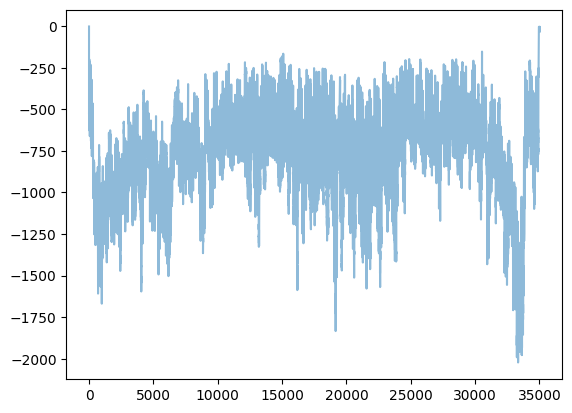

In [32]:
lala['Last_Industrie [kW]'].plot(alpha=0.5)